# IFEval 指令遵循评测：Qwen3-4B 的 CoT 预算实验

**模型**：`Qwen/Qwen3-4B` 原版（hybrid thinking），vLLM 加载与采样参数沿用 `gsm8k_test.ipynb`。
**数据**：`google/IFEval`，每题带 1–3 条可机检的指令。
**自变量**：CoT（thinking）预算，5 档，每档单独写一个 jsonl。

| 条件 | thinking | vLLM `thinking_token_budget` |
|---|---|---|
| `thinking_off` | 关（`enable_thinking=False`） | — |
| `thinking_budget_128` | 开 | 128 |
| `thinking_budget_256` | 开 | 256 |
| `thinking_budget_512` | 开 | 512 |
| `thinking_unlimited` | 开 | 不设（受 `max_tokens` 限制） |

**产物目录**：`IFEval_result/`（相对 notebook 所在目录）

- 逐题记录：`thinking_off.jsonl`、`thinking_budget_128.jsonl`、`thinking_budget_256.jsonl`、`thinking_budget_512.jsonl`、`thinking_unlimited.jsonl`
- 汇总：`summary_overall.csv`、`summary_by_instruction.csv`、`summary_by_k.csv`
- 图：`accuracy_overall_by_budget.png`、`accuracy_by_instruction.png`、`avg_followed_by_budget.png`、`accuracy_by_k.png`、`accuracy_full_vs_final.png`

**判定**：不调官方 `instruction_following_eval`，用本项目重写的逐条判定器（第 4 节）。

In [1]:
# ===== 全局配置：只需要改 MODEL_PATH =====
import ast, os, re, json, time
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 本地 Qwen3-4B 权重目录；用 1.7B 时改成 "../models/Qwen3-1.7B"
MODEL_PATH = "../models/Qwen3-4B"

# 采样参数 same with when thinking fails
TEMPERATURE = 0
TOP_P = 0.95
SEED = 0
MAX_NEW_TOKENS = 8192
MAX_MODEL_LEN = 16384

# 结果目录：notebook 同级的 IFEval_result/
RESULT_DIR = Path.cwd() / "IFEval_result"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

# 数据目录：向上找到含 pyproject.toml 的仓库根，数据放根目录的 ifeval/
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
DATA_DIR = ROOT / "ifeval"

# 五档 CoT 预算：thinking 关闭 / 128 / 256 / 512 / 不限制
CONDITIONS = [
    {"name": "thinking_off", "thinking": False, "budget": None},
    {"name": "thinking_budget_128", "thinking": True, "budget": 128},
    {"name": "thinking_budget_256", "thinking": True, "budget": 256},
    {"name": "thinking_budget_512", "thinking": True, "budget": 512},
    {"name": "thinking_unlimited", "thinking": True, "budget": None},
]
COND_NAMES = [c["name"] for c in CONDITIONS]
COND_LABELS = {
    "thinking_off": "no CoT",
    "thinking_budget_128": "CoT <=128",
    "thinking_budget_256": "CoT <=256",
    "thinking_budget_512": "CoT <=512",
    "thinking_unlimited": "CoT unlimited",
}

print("模型:", MODEL_PATH)
print("数据:", DATA_DIR)
print("结果:", RESULT_DIR)
print("条件:", COND_NAMES)

模型: ../models/Qwen3-4B
数据: /home/ubuntu-user/Desktop/Sandoleathy/CISC7404-Project/ifeval
结果: /home/ubuntu-user/Desktop/Sandoleathy/CISC7404-Project/Experiments/IFEval_result
条件: ['thinking_off', 'thinking_budget_128', 'thinking_budget_256', 'thinking_budget_512', 'thinking_unlimited']


## 1. 数据

IFEval 的 `kwargs` 是「每条指令一个参数 dict」，与 `instruction_id_list` 一一对应。
先落盘到 `ifeval/train.jsonl`（gitignore），之后统一从 jsonl 回读。

In [2]:
# ===== 读取 IFEval，落盘到 ifeval/train.jsonl =====
def read_jsonl(path):
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]


def load_ifeval():
    local = DATA_DIR / "train.jsonl"
    if local.exists():
        return pd.DataFrame(read_jsonl(local)), f"local ({local.name})"
    from datasets import load_dataset
    ds = load_dataset("google/IFEval", split="train")
    df = ds.to_pandas()
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    df.to_json(local, orient="records", lines=True, force_ascii=False)
    return df, "huggingface google/IFEval[train]"


def _as_list(x):
    """list / tuple / np.ndarray / 单个 dict / JSON 字符串统一成 list。

    datasets.to_pandas() 走 pyarrow，list 列每一行是 np.ndarray 而不是 list，
    所以不能只用 isinstance(x, (list, tuple)) 判断。
    """
    if x is None:
        return []
    if isinstance(x, dict):
        return [x]
    if isinstance(x, str):
        s = x.strip()
        if len(s) >= 2 and s[0] in "[(" and s[-1] in "])":
            try:
                v = ast.literal_eval(s)   # 兼容被存成字符串的列表字面量
                if isinstance(v, (list, tuple)):
                    return list(v)
            except Exception:
                pass
        return [x]
    try:
        return list(x)                    # list / tuple / np.ndarray
    except TypeError:
        return [x]


raw_df, source = load_ifeval()
df = raw_df.reset_index(drop=True)
df["uid"] = [f"ifeval-{i:04d}" for i in range(len(df))]
df["instruction_ids"] = df["instruction_id_list"].map(
    lambda x: [str(s) for s in _as_list(x)]
)
df["instruction_kwargs"] = df["kwargs"].map(
    lambda x: [d if isinstance(d, dict) else {} for d in _as_list(x)]
)
df["k"] = df["instruction_ids"].map(len)

print(f"数据来源: {source} | 题数: {len(df)}")
print(df[["prompt", "k"]].head(2).to_string(index=False, max_colwidth=70))

kdist = (df["k"].value_counts().sort_index()
           .rename_axis("k（每题约束条数）").reset_index(name="题数"))
kdist["占比"] = kdist["题数"] / len(df)
print("\n每题的约束条数分布：")
display(kdist.style.format({"占比": "{:.1%}"}))

inst = Counter(i for ids in df["instruction_ids"] for i in ids)
print("\n出现过的指令类型：", len(inst), "种")
for iid, n in inst.most_common():
    print(f"  {n:4d}  {iid}")

数据来源: local (train.jsonl) | 题数: 541
                                                                prompt  k
Write a 300+ word summary of the wikipedia page "https://en.wikiped...  3
I am planning a trip to Japan, and I would like thee to write an it...  1

每题的约束条数分布：


,k（每题约束条数）,题数,占比
0,1,305,56.4%
1,2,179,33.1%
2,3,57,10.5%



出现过的指令类型： 25 种
    66  punctuation:no_comma
    52  length_constraints:number_words
    52  length_constraints:number_sentences
    49  keywords:forbidden_words
    48  detectable_format:number_highlighted_sections
    42  keywords:frequency
    41  combination:repeat_prompt
    41  startend:quotation
    39  change_case:english_lowercase
    39  keywords:existence
    37  detectable_format:title
    33  keywords:letter_frequency
    31  detectable_format:number_bullet_lists
    31  language:response_language
    27  detectable_content:number_placeholders
    27  length_constraints:number_paragraphs
    26  startend:end_checker
    26  detectable_content:postscript
    25  change_case:english_capital
    25  change_case:capital_word_frequency
    24  combination:two_responses
    17  detectable_format:json_format
    14  detectable_format:multiple_sections
    12  length_constraints:nth_paragraph_first_word
    10  detectable_format:constrained_response


## 2. Prompt 与「思考块」切分

IFEval 的题目本身就是完整指令，因此**不加 system prompt**，直接作为唯一的 user 消息送进 chat template：

- `enable_thinking=True`：模板以 `<|im_start|>assistant\n` 结尾，模型自己写 ` thinking ... </think>`；
  预算用完时 vLLM 强制补 `</think>`，再继续写正式回答。
- `enable_thinking=False`：Qwen3-4B 的模板会预填一个空的 ` thinking\n\n</think>\n\n`，模型直接写回答。

判定对象有两个：

1. **全文**（默认指标）：prompt 之后生成的所有 token，含思考块。理由见 `record.md` 第 6 节——
   CoT 是否「把约束写坏」正是要看思考文本本身。
2. **仅最终回答**：`</think>` 之后的部分，用来区分「思考破坏格式」和「最终回答也不合格」。

In [3]:
# ===== Prompt 构造与「思考块」切分 =====
def build_messages(prompt):
    """IFEval 的指令就是 user 消息，不加额外的 system prompt。"""
    return [{"role": "user", "content": prompt}]


def prompt_kwargs(thinking):
    # 两种模式都从 assistant 处开始生成；enable_thinking=False 时模板插入空 thinking 块
    # 注意：换成 Qwen3-4B-Instruct-2507 时没有 enable_thinking 分支，要删掉这个 kwarg
    return {"add_generation_prompt": True, "enable_thinking": bool(thinking)}


def strip_thinking(text):
    """去掉 </think> 之前的思考文本，只留最终回答；thinking_off 时原样返回。"""
    s = str(text or "")
    if "</think>" in s:
        s = s.rsplit("</think>", 1)[1]
    return s.lstrip("\n").strip()

## 3. 重写的逐条判定器

官方 `instruction_following_eval` 依赖 `nltk` / `langdetect` / `immutabledict`，这里全部自己实现：

| 指令族 | 判定方式 |
|---|---|
| `change_case:*` | 全文无小写 / 无大写 / 大写词计数 |
| `combination:*` | 复述 prompt（归一化后大小写不敏感包含）；`******` 切成两段非空 |
| `detectable_content:*` | `*高亮*` 计数、`[方括号]` 占位符计数、结尾 `P.S.` |
| `detectable_format:*` | 固定三选一回答、JSON 可解析、`* ` 项目符号计数、`<<标题>>`、`SECTION`/`PARAGRAPH` 分节计数 |
| `keywords:*` | 整词匹配（大小写不敏感）的存在 / 频次 / 禁用词 / 字母频次 |
| `language:*` | 优先 `langdetect`，没装则按字符脚本判断（en/zh/ja/ko/ru/ar/...） |
| `length_constraints:*` | 句数（正则近似 `sent_tokenize`）、词数、段数（`***` 行或空行分隔）、第 n 段首词 |
| `punctuation:no_comma` | 全文不含半角/全角逗号 |
| `startend:*` | 结尾短语、整段被双引号包住 |

约定：

- 只算 **strict**（官方还有一套 loose，这里不做）。
- 未知指令或判定异常 → 记为 `passed=None`，**不计入**统计，并在 jsonl 里留 `error`。
- 判分口径与官方不完全一致（句子切分、词数、语言检测），跨论文比较时要注明。

In [4]:
# ===== 文本工具（不依赖 nltk / langdetect，缺失时自动降级） =====
WORD_RE = re.compile(r"[A-Za-z0-9]+(?:['’\-][A-Za-z0-9]+)*")
SENT_SPLIT_RE = re.compile(r"(?<=[.!?])\s+")


def norm_ws(text):
    return re.sub(r"\s+", " ", str(text or "")).strip()


def word_tokens(text):
    return WORD_RE.findall(str(text or ""))


def count_words(text):
    return len(word_tokens(text))


def split_sentences(text):
    """近似 nltk.sent_tokenize：按 . ! ? 之后的空白切句。"""
    text = str(text or "").strip()
    if not text:
        return []
    try:
        import nltk
        return [s for s in nltk.sent_tokenize(text) if s.strip()]
    except Exception:
        pass
    return [s for s in SENT_SPLIT_RE.split(text) if s.strip()]


def has_phrase(text, phrase):
    """大小写不敏感的整词匹配。"""
    if phrase is None or str(phrase) == "":
        return False
    return re.search(r"(?<!\w)" + re.escape(str(phrase)) + r"(?!\w)",
                     str(text or ""), re.IGNORECASE) is not None


def count_phrase(text, phrase):
    if phrase is None or str(phrase) == "":
        return 0
    return len(re.findall(r"(?<!\w)" + re.escape(str(phrase)) + r"(?!\w)",
                          str(text or ""), re.IGNORECASE))


def compare(count, threshold, relation):
    """IFEval 的 relation 只有 at least / less than（另兼容几种写法）。"""
    rel = str(relation or "at least").strip().lower()
    if rel in ("at least", ">=", "no less than"):
        return count >= threshold
    if rel in ("less than", "<"):
        return count < threshold
    if rel in ("at most", "<=", "no more than"):
        return count <= threshold
    if rel in ("more than", ">"):
        return count > threshold
    if rel in ("exactly", "=="):
        return count == threshold
    raise ValueError(f"未知 relation: {relation!r}")

In [5]:
# ===== 逐条指令判定；True/False 为结果，None 表示本实现不支持 =====
def _chk_capital(text, kw):
    return bool(re.search(r"[A-Za-z]", text)) and re.search(r"[a-z]", text) is None


def _chk_lowercase(text, kw):
    return bool(re.search(r"[A-Za-z]", text)) and re.search(r"[A-Z]", text) is None


def _chk_capital_word_frequency(text, kw):
    n = sum(1 for w in word_tokens(text) if w.isupper())
    return compare(n, int(kw.get("capital_frequency", 0)),
                   kw.get("capital_relation", "at least"))


def _chk_repeat_prompt(text, kw):
    prompt = norm_ws(kw.get("prompt_to_repeat", "")).lower()
    return bool(prompt) and prompt in norm_ws(text).lower()


def _chk_two_responses(text, kw):
    parts = str(text or "").split("******")
    return len(parts) == 2 and all(p.strip() for p in parts)


def _chk_highlighted_sections(text, kw):
    need = int(kw.get("num_highlights", 1))
    return len(re.findall(r"\*[^*\n]+\*", str(text or ""))) >= need


def _chk_number_placeholders(text, kw):
    """方括号占位符，如 [address]；题面 27/27 都是 at least。"""
    need = int(kw.get("num_placeholders", 0) or 0)
    return len(re.findall(r"\[[^\[\]\n]*\]", str(text or ""))) >= need


def _chk_number_paragraphs(text, kw):
    """段落数：题面一律 exactly，分隔符是 *** 行或空行。"""
    need = int(kw.get("num_paragraphs", 0) or 0)
    parts = re.split(r"(?m)^\s*\*{3,}\s*$|\n\s*\n", str(text or ""))
    return len([p for p in parts if p.strip()]) == need


def _chk_multiple_sections(text, kw):
    """按 section_spliter 的字面计数；2/14 题面写 at least，故用 >=。"""
    splitter = str(kw.get("section_spliter") or "")
    need = int(kw.get("num_sections", 0) or 0)
    if not splitter:
        return None
    return str(text or "").count(splitter) >= need


def _chk_postscript(text, kw):
    marker = str(kw.get("postscript_marker", "P.S.")).lower()
    lines = [l.strip() for l in str(text or "").strip().splitlines() if l.strip()]
    return bool(lines) and lines[-1].lower().startswith(marker)


_CONSTRAINED_RESPONSE_OPTIONS = (
    "my answer is yes.",
    "my answer is no.",
    "my answer is maybe.",
)


def _chk_constrained_response(text, kw):
    low = norm_ws(text).lower()
    return any(opt in low for opt in _CONSTRAINED_RESPONSE_OPTIONS)


def _chk_json_format(text, kw):
    s = str(text or "").strip()
    if s.startswith("```"):
        s = re.sub(r"^```[A-Za-z]*\s*", "", s)
        s = re.sub(r"\s*```$", "", s).strip()
    try:
        json.loads(s)
        return True
    except Exception:
        pass
    for pat in (r"\{.*\}", r"\[.*\]"):
        m = re.search(pat, s, flags=re.DOTALL)
        if m:
            try:
                json.loads(m.group(0))
                return True
            except Exception:
                continue
    return False


def _chk_number_bullet_lists(text, kw):
    need = int(kw.get("num_bullets", 1))
    bullets = re.findall(r"^\s*\*(?!\*)\s*\S.*$", str(text or ""), flags=re.MULTILINE)
    return len(bullets) == need


def _chk_title(text, kw):
    return re.search(r"<<[^\n<>]+>>", str(text or "")) is not None


def _chk_keywords_existence(text, kw):
    keywords = kw.get("keywords", [])
    if isinstance(keywords, str):
        keywords = [keywords]
    return all(has_phrase(text, w) for w in keywords)


def _chk_keywords_frequency(text, kw):
    n = count_phrase(text, kw.get("keyword", ""))
    return compare(n, int(kw.get("frequency", 0)), kw.get("relation", "at least"))


def _chk_forbidden_words(text, kw):
    words = kw.get("forbidden_words", [])
    if isinstance(words, str):
        words = [words]
    return not any(has_phrase(text, w) for w in words)


def _chk_letter_frequency(text, kw):
    letters = kw.get("letter", [])
    if isinstance(letters, str):
        letters = [letters]
    letters = {str(c).lower() for c in letters}
    n = sum(1 for c in str(text or "").lower() if c in letters)
    return compare(n, int(kw.get("let_frequency", 0)),
                   kw.get("let_relation", "at least"))


_SCRIPT_RE = {
    "zh": r"[\u4e00-\u9fff]",
    "ja": r"[\u3040-\u30ff\u4e00-\u9fff]",
    "ko": r"[\uac00-\ud7af]",
    "ru": r"[\u0400-\u04ff]",
    "ar": r"[\u0600-\u06ff]",
    "hi": r"[\u0900-\u097f]",
    "th": r"[\u0e00-\u0e7f]",
    "el": r"[\u0370-\u03ff]",
}


def _chk_response_language(text, kw):
    lang = str(kw.get("language", "")).lower()
    s = str(text or "")
    try:
        from langdetect import detect
        return detect(s) == lang
    except Exception:
        pass
    if lang in _SCRIPT_RE:
        return re.search(_SCRIPT_RE[lang], s) is not None
    if lang in ("en", "english"):
        letters = [c for c in s if c.isalpha()]
        if not letters:
            return False
        return sum(ord(c) < 128 for c in letters) / len(letters) > 0.9
    return None


def _chk_number_sentences(text, kw):
    return compare(len(split_sentences(text)), int(kw.get("num_sentences", 0)),
                   kw.get("relation", "at least"))


def _chk_number_words(text, kw):
    return compare(count_words(text), int(kw.get("num_words", 0)),
                   kw.get("relation", "at least"))


def _chk_nth_paragraph_first_word(text, kw):
    nth = int(kw.get("nth_paragraph", 1))
    first = str(kw.get("first_word", "")).strip().lower()
    paras = [p.strip() for p in re.split(r"\n\s*\n", str(text or "")) if p.strip()]
    need = int(kw.get("num_paragraphs", 0) or 0)
    if need and len(paras) != need:   # 题面一律 exactly N paragraphs
        return False
    if len(paras) < nth:
        return False
    tokens = word_tokens(paras[nth - 1])
    return bool(tokens) and tokens[0].lower() == first


def _chk_no_comma(text, kw):
    return ("," not in str(text or "")) and ("，" not in str(text or ""))


def _chk_end_phrase(text, kw):
    phrase = str(kw.get("end_phrase", ""))
    return bool(phrase) and str(text or "").strip().endswith(phrase)


def _chk_quotation(text, kw):
    s = str(text or "").strip()
    return len(s) >= 2 and s.startswith('"') and s.endswith('"')

In [6]:
# ===== 指令 id → 判定函数 =====
# 数据里实际出现的 25 种 id 全部覆盖；个别别名保留用于版本差异兜底
CHECKERS = {
    "change_case:capital_word_frequency": _chk_capital_word_frequency,
    "change_case:english_capital": _chk_capital,
    "change_case:english_lowercase": _chk_lowercase,
    "combination:repeat_prompt": _chk_repeat_prompt,
    "combination:two_responses": _chk_two_responses,
    "detectable_content:number_highlighted_sections": _chk_highlighted_sections,
    "detectable_content:number_placeholders": _chk_number_placeholders,
    "detectable_content:postscript": _chk_postscript,
    "detectable_format:number_highlighted_sections": _chk_highlighted_sections,
    "detectable_format:multiple_sections": _chk_multiple_sections,
    "detectable_format:postscript": _chk_postscript,
    "detectable_format:constrained_response": _chk_constrained_response,
    "detectable_format:json_format": _chk_json_format,
    "detectable_format:number_bullet_lists": _chk_number_bullet_lists,
    "detectable_format:title": _chk_title,
    "keywords:existence": _chk_keywords_existence,
    "keywords:frequency": _chk_keywords_frequency,
    "keywords:forbidden_words": _chk_forbidden_words,
    "keywords:letter_frequency": _chk_letter_frequency,
    "language:response_language": _chk_response_language,
    "length_constraints:number_sentences": _chk_number_sentences,
    "length_constraints:number_words": _chk_number_words,
    "length_constraints:number_paragraphs": _chk_number_paragraphs,
    "length_constraints:nth_paragraph_first_word": _chk_nth_paragraph_first_word,
    "punctuation:no_comma": _chk_no_comma,
    "startend:end_checker": _chk_end_phrase,
    "startend:quotation": _chk_quotation,
}


def verify_instructions(text, instruction_ids, kwargs_list):
    """对一条回答逐条判定，返回 [{'id', 'passed', 'error'}]。"""
    results = []
    for i, iid in enumerate(instruction_ids):
        kw = kwargs_list[i] if i < len(kwargs_list) and isinstance(kwargs_list[i], dict) else {}
        fn = CHECKERS.get(iid)
        if fn is None:
            results.append({"id": iid, "passed": None, "error": "unsupported"})
            continue
        try:
            passed = fn(text, kw)
        except Exception as e:
            results.append({"id": iid, "passed": None, "error": f"{type(e).__name__}: {e}"})
            continue
        results.append({"id": iid, "passed": None if passed is None else bool(passed), "error": None})
    return results


def tally(per_instruction):
    """压成 (通过条数, 参与判定的条数, 是否全过)。"""
    vals = [x["passed"] for x in per_instruction if x["passed"] is not None]
    all_pass = bool(all(vals)) if vals else None
    return sum(vals), len(vals), all_pass

## 4. vLLM 推理

沿用 `gsm8k_test.ipynb` 的配置：`dtype="bfloat16"`、`gpu_memory_utilization=0.85`、
`max_model_len=16384`，外加五档 `thinking_token_budget`。

> 这套是 4B 在 gsm8k 上跑通的配置，不是 `AGENTS.md` 第 3 节 1.7B 的 8GB 模板。
> T4 等 Turing 卡要把 `dtype` 改成 `"half"`；显存不够就调小 `MAX_MODEL_LEN` / `gpu_memory_utilization`。

In [7]:
# ===== vLLM 推理：五档 CoT 预算，每档一个 jsonl =====
os.environ.setdefault("VLLM_USE_FLASHINFER_SAMPLER", "0")  # 无 nvcc 时避免 FlashInfer 采样器 JIT 失败

from vllm import LLM, SamplingParams
from vllm.config import ReasoningConfig

llm = LLM(
    model=MODEL_PATH,
    dtype="bfloat16",
    gpu_memory_utilization=0.85,
    max_model_len=MAX_MODEL_LEN,
    reasoning_config=ReasoningConfig(
        reasoning_start_str="<|im_start|>assistant\n",
        reasoning_end_str="</think>\n\n",
    ),
)
tokenizer = llm.get_tokenizer()

prompts = {
    thinking: [tokenizer.apply_chat_template(build_messages(p), tokenize=False,
                                             **prompt_kwargs(thinking))
               for p in df["prompt"]]
    for thinking in (True, False)
}

records = df.to_dict("records")

for cond in CONDITIONS:
    name = cond["name"]
    path = RESULT_DIR / f"{name}.jsonl"

    sp = SamplingParams(
        temperature=TEMPERATURE,
        top_p=TOP_P,
        max_tokens=MAX_NEW_TOKENS,
        seed=SEED,
        thinking_token_budget=cond["budget"],   # None = 不限制
    )

    t0 = time.time()
    outputs = llm.generate(prompts[cond["thinking"]], sp)
    elapsed = time.time() - t0

    rows = []
    for r, out in zip(records, outputs):
        text = out.outputs[0].text
        final = strip_thinking(text)
        per_full = verify_instructions(text, r["instruction_ids"], r["instruction_kwargs"])
        per_final = verify_instructions(final, r["instruction_ids"], r["instruction_kwargs"])
        n_pass, n_check, all_pass = tally(per_full)
        n_pass_final, n_check_final, all_pass_final = tally(per_final)
        rows.append({
            "condition": name,
            "thinking": cond["thinking"],
            "thinking_budget": cond["budget"],
            "uid": r["uid"],
            "k": int(r["k"]),
            "instruction_id_list": r["instruction_ids"],
            "n_check": n_check,
            "n_pass": n_pass,
            "all_pass": all_pass,
            "n_check_final": n_check_final,
            "n_pass_final": n_pass_final,
            "all_pass_final": all_pass_final,
            "per_instruction": per_full,
            "per_instruction_final": per_final,
            "n_tokens": len(out.outputs[0].token_ids),
            "finish_reason": out.outputs[0].finish_reason,
            "output": text,
            "output_final": final,
            "prompt": r["prompt"],
        })

    with open(path, "w", encoding="utf-8") as f:
        for row in rows:
            f.write(json.dumps(row, ensure_ascii=False) + "\n")

    strict_vals = [row["all_pass"] for row in rows if row["all_pass"] is not None]
    strict = sum(strict_vals) / len(strict_vals) if strict_vals else float("nan")
    total_pass = sum(row["n_pass"] for row in rows)
    total_check = sum(row["n_check"] for row in rows)
    level = total_pass / total_check if total_check else float("nan")
    avg_tok = sum(row["n_tokens"] for row in rows) / len(rows)
    print(f"{name}: prompt级={strict:.2%} | 指令级={level:.2%} | "
          f"平均 {avg_tok:.0f} tokens | 用时 {elapsed / 60:.1f} min -> {path}")

W1112 19:26:26.220000 142081 torch/_opaque_base.py:6] torch._opaque_base is deprecated, use torch._custom_class_base instead
W1112 19:26:26.220000 142081 torch/_library/opaque_object.py:288] register_opaque_type is deprecated, use register_custom_class instead
W1112 19:26:26.221000 142081 torch/_library/opaque_object.py:211] typ='value' is deprecated, use typ='constant' instead


(MainProcess pid=142081) INFO 11-12 19:26:28 [startup.py:96] non-default args: {'dtype': 'bfloat16', 'max_model_len': 16384, 'gpu_memory_utilization': 0.85, 'disable_log_stats': True, 'reasoning_config': ReasoningConfig(reasoning_parser='', reasoning_start_str='<|im_start|>assistant\n', reasoning_end_str='</think>\n\n'), 'model': '../models/Qwen3-4B'}
(MainProcess pid=142081) INFO 11-12 19:26:28 [model.py:744] Resolved architecture: Qwen3ForCausalLM
(MainProcess pid=142081) INFO 11-12 19:26:28 [model.py:2170] Using max model len 16384
(MainProcess pid=142081) INFO 11-12 19:26:28 [scheduler.py:310] Chunked prefill is enabled with max_num_batched_tokens=8192.
(MainProcess pid=142081) INFO 11-12 19:26:28 [kernel.py:480] Final IR op priority after setting platform defaults: IrOpPriorityConfig(rms_norm=['native'], fused_add_rms_norm=['native'], gelu_and_mul_sparse=['triton', 'native'])
(EngineCore pid=143991) INFO 11-12 19:26:30 [core.py:139] Initializing a V1 LLM engine (v0.33.0) with conf

Loading safetensors checkpoint shards:   0% Completed | 0/3 [00:00<?, ?it/s]


(EngineCore pid=143991) INFO 11-12 19:26:33 [default_loader.py:506] Loading weights took 0.66 seconds
(EngineCore pid=143991) INFO 11-12 19:26:34 [model_runner.py:428] Model loading took 7.56 GiB memory and 2.552350 seconds
(EngineCore pid=143991) INFO 11-12 19:26:34 [topk_topp_sampler.py:121] FlashInfer top-p/top-k sampling disabled via VLLM_USE_FLASHINFER_SAMPLER=0.
(EngineCore pid=143991) INFO 11-12 19:26:34 [torch_utils.py:281] Reducing Torch threads from 16 to 1 for serving. Set OMP_NUM_THREADS in the external environment to override.
(EngineCore pid=143991) INFO 11-12 19:26:34 [utils.py:381] Using LBNHC KV cache layout.
(EngineCore pid=143991) INFO 11-12 19:26:34 [caching.py:342] reconstructed serializable fn from standalone compile artifacts. num_artifacts=3 num_submods=37
(EngineCore pid=143991) INFO 11-12 19:26:34 [decorators.py:326] [backbone] Directly load AOT compilation from path /home/ubuntu-user/.cache/vllm/torch_compile_cache/torch_aot_compile/8e3666c503856d0560ccc747a7

Capturing CUDA graphs (FULL): 100%|██████████████| 2/2 [00:00<00:00, 39.58it/s]


(EngineCore pid=143991) INFO 11-12 19:26:39 [model_runner.py:1163] Graph capturing finished in 3 secs, took 0.38 GiB
(EngineCore pid=143991) INFO 11-12 19:26:39 [gpu_worker.py:772] Available KV cache memory: 11.22 GiB
(EngineCore pid=143991) INFO 11-12 19:26:39 [gpu_worker.py:787] CUDA graph memory profiling is enabled (default since v0.21.0). The current --gpu-memory-utilization=0.8500 is equivalent to --gpu-memory-utilization=0.8317 without CUDA graph memory profiling. To maintain the same effective KV cache size as before, increase --gpu-memory-utilization to 0.8683. To disable, set VLLM_MEMORY_PROFILER_ESTIMATE_CUDAGRAPHS=0.
(EngineCore pid=143991) INFO 11-12 19:26:39 [kv_cache_utils.py:1147] GPU KV cache size: 81,728 tokens, Maximum concurrency for 16,384 tokens per request: 4.99x
(EngineCore pid=143991) INFO 11-12 19:26:39 [kernel_warmup.py:179] JIT kernel warmup starting.
(EngineCore pid=143991) INFO 11-12 19:26:39 [kernel_warmup.py:192] JIT kernel warmup finished in 0.00s.


... (14 outputs left out)

thinking_budget_512: prompt级=40.64% | 指令级=53.94% | 平均 974 tokens | 用时 5.4 min -> /home/ubuntu-user/Desktop/Sandoleathy/CISC7404-Project/Experiments/IFEval_result/thinking_budget_512.jsonl


Rendering prompts:   0%|          | 0/541 [00:00<?, ?it/s]

Processed prompts: 100%|█| 541/541 [10:45<00:00,  1.19s/it, est. speed input: 4

thinking_unlimited: prompt级=40.08% | 指令级=53.69% | 平均 1435 tokens | 用时 10.8 min -> /home/ubuntu-user/Desktop/Sandoleathy/CISC7404-Project/Experiments/IFEval_result/thinking_unlimited.jsonl


## 5. 汇总

三个核心量：

- **prompt-level strict**：一题的所有约束全过才算对 → 「整体正确率」
- **instruction-level**：所有（题 × 约束）里通过的比例 → 单条约束正确率的总体平均
- **avg_followed**：每题平均遵循了几条 → 「平均遵循约束条数」

带 `_final` 后缀的列用「去掉思考块后的最终回答」判定，只作对照。

In [8]:
# ===== 汇总：整体正确率 / 分指令正确率 / 平均遵循条数 =====
dfs = {name: pd.DataFrame(read_jsonl(RESULT_DIR / f"{name}.jsonl")) for name in COND_NAMES}


def rate(series):
    """把 True/False/None 列转成通过率；全为空时返回 nan。"""
    s = pd.to_numeric(series, errors="coerce").dropna()
    return float(s.mean()) if len(s) else float("nan")


def mean_or_nan(xs):
    xs = list(xs)
    return float(np.mean(xs)) if xs else float("nan")


def build_long(dfs, key):
    """每行 = (条件, 题目, 约束)；key 选 per_instruction / per_instruction_final。"""
    rows = []
    for name, r in dfs.items():
        for _, row in r.iterrows():
            for item in row[key]:
                rows.append({
                    "condition": name,
                    "uid": row["uid"],
                    "k": int(row["k"]),
                    "instruction_id": item["id"],
                    "passed": item["passed"],
                })
    out = pd.DataFrame(rows)
    out["passed_num"] = pd.to_numeric(out["passed"], errors="coerce")
    return out


long_df = build_long(dfs, "per_instruction")
long_final_df = build_long(dfs, "per_instruction_final")

overall = pd.DataFrame([{
    "condition": name,
    "prompts": len(r),
    "prompt_strict": rate(r["all_pass"]),
    "instruction_level": mean_or_nan(
        long_df.loc[long_df["condition"] == name, "passed_num"].dropna()),
    "avg_followed": mean_or_nan(r["n_pass"]),
    "avg_k": mean_or_nan(r["k"]),
    "prompt_strict_final": rate(r["all_pass_final"]),
    "instruction_level_final": mean_or_nan(
        long_final_df.loc[long_final_df["condition"] == name, "passed_num"].dropna()),
    "avg_followed_final": mean_or_nan(r["n_pass_final"]),
    "avg_tokens": mean_or_nan(r["n_tokens"]),
    "truncated": mean_or_nan(r["finish_reason"].eq("length")),
} for name, r in dfs.items()]).set_index("condition").loc[COND_NAMES].reset_index()

print("整体汇总：")
print(overall.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
overall.to_csv(RESULT_DIR / "summary_overall.csv", index=False, encoding="utf-8-sig")

by_inst = (long_df.dropna(subset=["passed_num"])
                  .groupby(["instruction_id", "condition"])["passed_num"]
                  .agg(n="size", pass_rate="mean")
                  .reset_index())
by_inst.to_csv(RESULT_DIR / "summary_by_instruction.csv", index=False, encoding="utf-8-sig")

inst_wide = (by_inst.pivot(index="instruction_id", columns="condition", values="pass_rate")
                    .reindex(columns=COND_NAMES).sort_index())
print("\n分指令正确率（行 = 指令类型，列 = CoT 预算）：")
display(inst_wide.style.format("{:.2f}", na_rep="—"))

by_k = pd.DataFrame([{
    "condition": name,
    "k": int(k),
    "prompts": len(g),
    "prompt_strict": rate(g["all_pass"]),
} for name, r in dfs.items() for k, g in r.groupby("k")]).sort_values(["k", "condition"])
by_k.to_csv(RESULT_DIR / "summary_by_k.csv", index=False, encoding="utf-8-sig")

print("\n按约束条数 k 分组：")
display(by_k.pivot(index="k", columns="condition", values="prompt_strict")
             .reindex(columns=COND_NAMES).style.format("{:.2f}", na_rep="—"))

n_na = int(long_df["passed_num"].isna().sum())
print(f"\n未被判定的（题 × 约束）: {n_na} / {len(long_df)}")

整体汇总：
          condition  prompts  prompt_strict  instruction_level  avg_followed  avg_k  prompt_strict_final  instruction_level_final  avg_followed_final  avg_tokens  truncated
       thinking_off      541         0.7675             0.8337        1.2514 1.5416               0.7675                   0.8337              1.2514    470.5970     0.0166
thinking_budget_128      541         0.4102             0.5554        0.8336 1.5416               0.7958                   0.8608              1.2921    792.7708     0.0388
thinking_budget_256      541         0.4121             0.5480        0.8226 1.5416               0.8223                   0.8719              1.3087    797.1479     0.0240
thinking_budget_512      541         0.4064             0.5394        0.8096 1.5416               0.8223                   0.8781              1.3179    974.4658     0.0259
 thinking_unlimited      541         0.4008             0.5369        0.8059 1.5416               0.7845                   0.8485

condition,thinking_off,thinking_budget_128,thinking_budget_256,thinking_budget_512,thinking_unlimited
instruction_id,,,,,
change_case:capital_word_frequency,0.76,0.72,0.72,0.72,0.72
change_case:english_capital,0.84,0.00,0.00,0.00,0.00
change_case:english_lowercase,0.92,0.00,0.00,0.00,0.00
combination:repeat_prompt,0.73,0.78,0.68,0.73,0.76
combination:two_responses,0.96,0.88,0.88,0.88,0.92
detectable_content:number_placeholders,0.93,0.96,1.00,1.00,0.96
detectable_content:postscript,0.69,0.65,0.81,0.69,0.69
detectable_format:constrained_response,1.00,1.00,1.00,1.00,1.00
detectable_format:json_format,1.00,1.00,1.00,1.00,0.88



按约束条数 k 分组：


condition,thinking_off,thinking_budget_128,thinking_budget_256,thinking_budget_512,thinking_unlimited
k,,,,,
1,0.87,0.58,0.58,0.56,0.55
2,0.67,0.23,0.23,0.23,0.22
3,0.56,0.12,0.14,0.16,0.18



未被判定的（题 × 约束）: 110 / 4170


## 6. 图

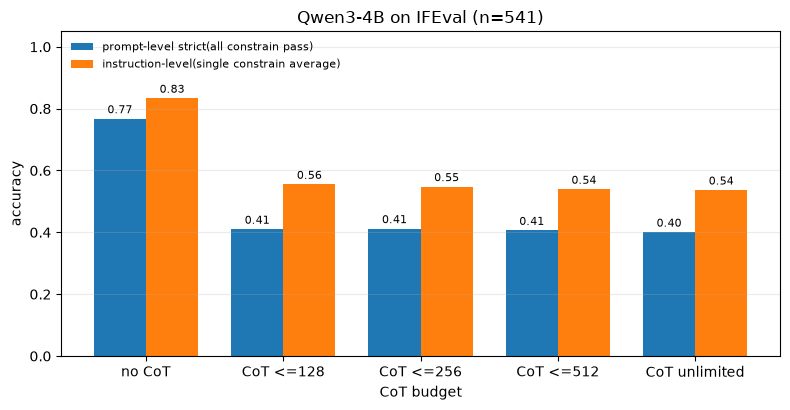

In [9]:
# ===== 图 1：整体正确率 vs CoT 预算 =====
x = np.arange(len(COND_NAMES))
labels = [COND_LABELS[n] for n in COND_NAMES]
w = 0.38

fig, ax = plt.subplots(figsize=(8, 4.2))
b1 = ax.bar(x - w / 2, overall["prompt_strict"], width=w,
            label="prompt-level strict(all constrain pass)")
b2 = ax.bar(x + w / 2, overall["instruction_level"], width=w,
            label="instruction-level(single constrain average)")
ax.bar_label(b1, fmt="%.2f", fontsize=8, padding=2)
ax.bar_label(b2, fmt="%.2f", fontsize=8, padding=2)
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 1.05)
ax.set_ylabel("accuracy")
ax.set_xlabel("CoT budget")
ax.set_title(f"Qwen3-4B on IFEval (n={len(df)})")
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout()
plt.savefig(RESULT_DIR / "accuracy_overall_by_budget.png", dpi=160, bbox_inches="tight")
plt.show()

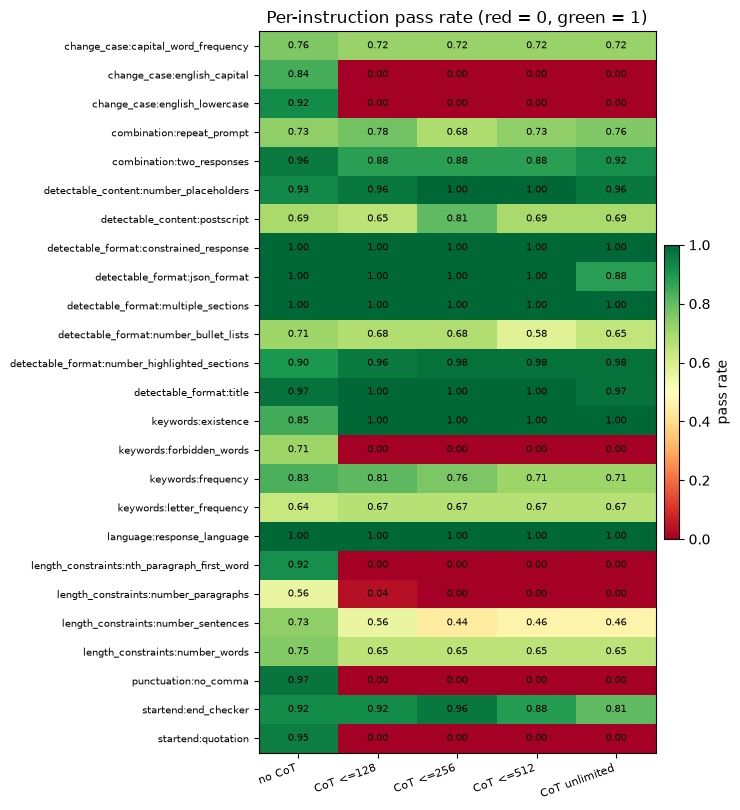

In [10]:
# ===== 图 2：分指令正确率热力图 =====
mat = inst_wide.reindex(columns=COND_NAMES)
vals = mat.values.astype(float)

fig, ax = plt.subplots(figsize=(7.5, 8.2))
im = ax.imshow(vals, aspect="auto", vmin=0, vmax=1, cmap="RdYlGn")
ax.set_xticks(range(len(COND_NAMES)))
ax.set_xticklabels(labels, rotation=20, ha="right", fontsize=8)
ax.set_yticks(range(len(mat.index)))
ax.set_yticklabels(mat.index, fontsize=7.5)
for i in range(vals.shape[0]):
    for j in range(vals.shape[1]):
        if not np.isnan(vals[i, j]):
            ax.text(j, i, f"{vals[i, j]:.2f}", ha="center", va="center", fontsize=7)
cbar = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
cbar.set_label("pass rate")
ax.set_title("Per-instruction pass rate (red = 0, green = 1)")
plt.tight_layout()
plt.savefig(RESULT_DIR / "accuracy_by_instruction.png", dpi=160, bbox_inches="tight")
plt.show()

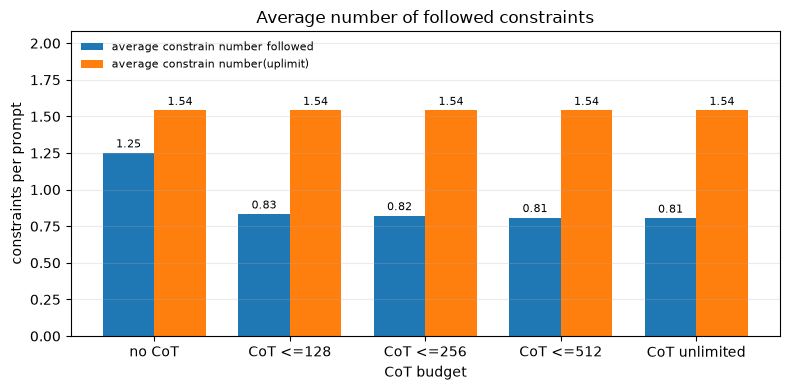

In [11]:
# ===== 图 3：平均遵循条数 vs CoT 预算 =====
fig, ax = plt.subplots(figsize=(8, 4.0))
b1 = ax.bar(x - w / 2, overall["avg_followed"], width=w, label="average constrain number followed")
b2 = ax.bar(x + w / 2, overall["avg_k"], width=w, label="average constrain number(uplimit)")
ax.bar_label(b1, fmt="%.2f", fontsize=8, padding=2)
ax.bar_label(b2, fmt="%.2f", fontsize=8, padding=2)
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("constraints per prompt")
ax.set_xlabel("CoT budget")
ax.set_ylim(0, max(overall["avg_k"].max() * 1.35, 0.5))
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False, fontsize=8, loc="upper left")
ax.set_title("Average number of followed constraints")
plt.tight_layout()
plt.savefig(RESULT_DIR / "avg_followed_by_budget.png", dpi=160, bbox_inches="tight")
plt.show()

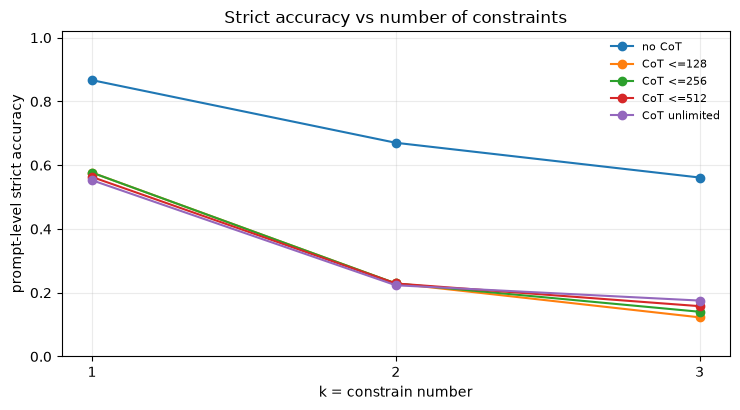

In [12]:
# ===== 图 4：prompt 级正确率随约束条数 k 的变化 =====
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for name in COND_NAMES:
    sub = by_k.loc[by_k["condition"] == name].sort_values("k")
    ax.plot(sub["k"], sub["prompt_strict"], marker="o", label=COND_LABELS[name])
ax.set_xticks(sorted(by_k["k"].unique()))
ax.set_xlabel("k = constrain number")
ax.set_ylabel("prompt-level strict accuracy")
ax.set_ylim(0, 1.02)
ax.grid(alpha=0.25)
ax.legend(frameon=False, fontsize=8)
ax.set_title("Strict accuracy vs number of constraints")
plt.tight_layout()
plt.savefig(RESULT_DIR / "accuracy_by_k.png", dpi=160, bbox_inches="tight")
plt.show()

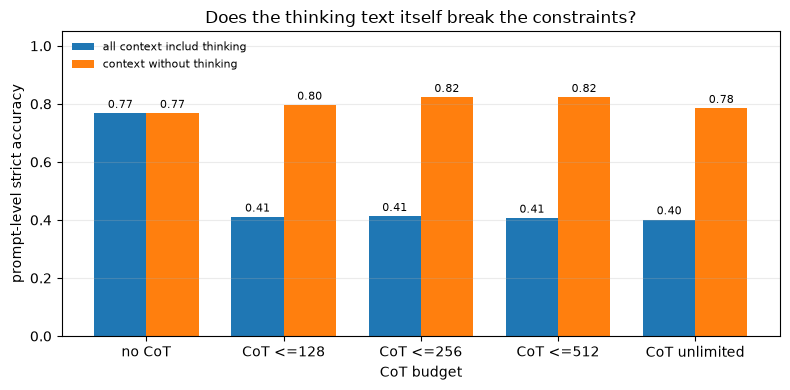

In [13]:
# ===== 图 5：全文判定 vs 仅最终回答 =====
fig, ax = plt.subplots(figsize=(8, 4.0))
b1 = ax.bar(x - w / 2, overall["prompt_strict"], width=w, label="all context includ thinking")
b2 = ax.bar(x + w / 2, overall["prompt_strict_final"], width=w, label="context without thinking")
ax.bar_label(b1, fmt="%.2f", fontsize=8, padding=2)
ax.bar_label(b2, fmt="%.2f", fontsize=8, padding=2)
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 1.05)
ax.set_ylabel("prompt-level strict accuracy")
ax.set_xlabel("CoT budget")
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False, fontsize=8, loc="upper left")
ax.set_title("Does the thinking text itself break the constraints?")
plt.tight_layout()
plt.savefig(RESULT_DIR / "accuracy_full_vs_final.png", dpi=160, bbox_inches="tight")
plt.show()

## 7. 注意事项

1. **判定器是重写的简化版**。只算 strict，不做 loose；句子切分在没有 `nltk` 时用正则近似；
   词数用正则 token；`language:response_language` 在没有 `langdetect` 时按字符脚本判断。
   因此数值不能直接和官方 IFEval 排行榜对齐，只能在本 notebook 内部横向比较。
2. **`thinking_off` 不是「没有 prompt」**：Qwen3-4B 的模板会插入空的 ` thinking\n\n</think>\n\n`，
   模型直接写回答。换成 `Qwen3-4B-Instruct-2507` 时要删掉 `enable_thinking` kwarg（该模板没有这个分支）。
3. **`thinking_unlimited` 不是真的无限**：仍受 `MAX_NEW_TOKENS=8192` 和 `MAX_MODEL_LEN=16384` 限制，
   看 `summary_overall.csv` 的 `truncated` 列。
4. **单次采样**：`temperature=0.6` 沿项目统一值，曲线有采样噪声；要更稳就改 0 做贪心。
5. **k=3 的题很少**，`summary_by_k.csv` 里同时给了 `prompts`，读曲线时先看样本量。
6. **全文 vs 最终回答**：`_final` 列去掉了 `</think>` 之前的内容。若某档预算下模型把答案也写在思考块里，
   `output_final` 会接近空串，所有约束都会判失败——这是真实行为，不是判定器 bug，看 jsonl 原文确认。
7. 原始输出、逐条判定（含 `error` 字段）都在 `IFEval_result/{condition}.jsonl`，排查错误直接读原文。
8. **三种定量指令的口径**：`number_placeholders` 数方括号 `[...]`、用 `>=`（题面 27/27 都是 at least）；
   `number_paragraphs` 按 `***` 行或空行切段、用 `==`（题面一律 exactly）；
   `multiple_sections` 按 `section_spliter` 字面计数、用 `>=`（14 条里有 2 条题面写 at least）。

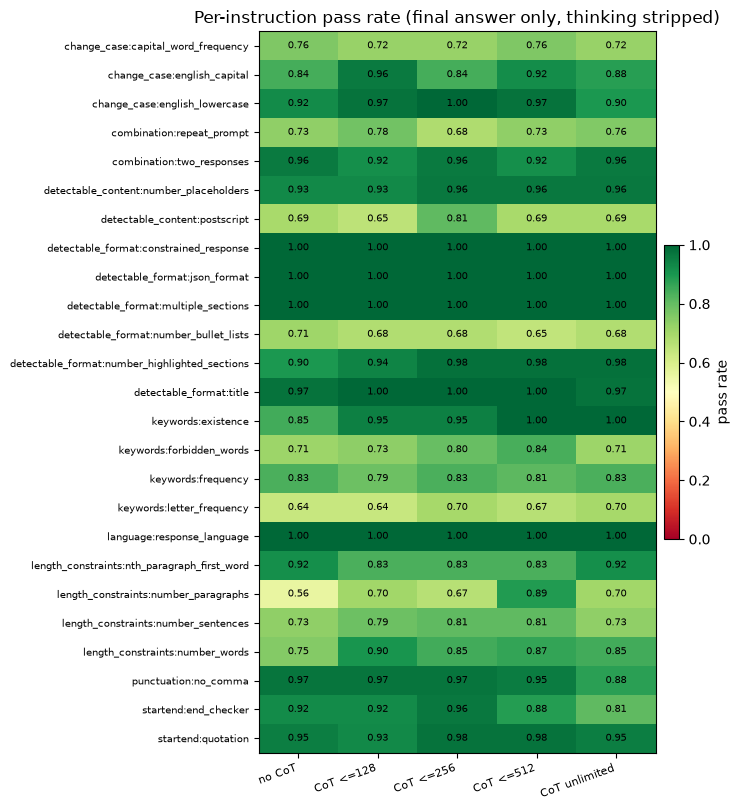

In [14]:
# ===== 图 6：分指令正确率热力图（去掉 thinking，只看最终回答） =====
mat_final = (long_final_df.dropna(subset=["passed_num"])
                          .groupby(["instruction_id", "condition"])["passed_num"]
                          .agg(n="size", pass_rate="mean")
                          .reset_index()
                          .pivot(index="instruction_id", columns="condition", values="pass_rate")
                          .reindex(columns=COND_NAMES)
                          .sort_index())
vals_final = mat_final.values.astype(float)

fig, ax = plt.subplots(figsize=(7.5, 8.2))
im = ax.imshow(vals_final, aspect="auto", vmin=0, vmax=1, cmap="RdYlGn")
ax.set_xticks(range(len(COND_NAMES)))
ax.set_xticklabels([COND_LABELS[n] for n in COND_NAMES], rotation=20, ha="right", fontsize=8)
ax.set_yticks(range(len(mat_final.index)))
ax.set_yticklabels(mat_final.index, fontsize=7.5)
for i in range(vals_final.shape[0]):
    for j in range(vals_final.shape[1]):
        if not np.isnan(vals_final[i, j]):
            ax.text(j, i, f"{vals_final[i, j]:.2f}", ha="center", va="center", fontsize=7)
cbar = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
cbar.set_label("pass rate")
ax.set_title("Per-instruction pass rate (final answer only, thinking stripped)")
plt.tight_layout()
plt.savefig(RESULT_DIR / "accuracy_by_instruction_final.png", dpi=160, bbox_inches="tight")
plt.show()